In [11]:
# Anomaly Detection with PCA and Gaussian Model using Validation Set

# 1. Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [12]:

from sklearn.metrics import f1_score, confusion_matrix

# 2. Load Dataset
df = pd.read_csv("creditcard.csv")
print("Data Loaded. Shape:", df.shape)

# 3. Class Distribution
print("\nClass Distribution:")
print(df['Class'].value_counts())
print("\nPercentage Distribution:")
print(df['Class'].value_counts(normalize=True) * 100)

# 4. Preprocess
features = df.drop(['Time', 'Class'], axis=1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)
y_true = df['Class'].values

Data Loaded. Shape: (284807, 31)

Class Distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Percentage Distribution:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


Shape: (284807, 31)

Columns:
 ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Missing values:
 Time      0
V16       0
Amount    0
V28       0
V27       0
V26       0
V25       0
V24       0
V23       0
V22       0
dtype: int64

Summary statistics:


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.168375e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.416908e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.074095e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,9.604066e-16,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.487313e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.556467e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.213481e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.406331e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995



Top 10 most positively skewed features:


Amount    16.977724
V28       11.192091
V21        3.592991
V7         2.553907
V6         1.826581
V10        1.187141
V4         0.676292
V26        0.576693
V9         0.554680
V11        0.356506
dtype: float64


Top 10 most negatively skewed features:


V14   -1.995176
V20   -2.037155
V3    -2.240155
V12   -2.278401
V5    -2.425901
V1    -3.280667
V17   -3.844914
V2    -4.624866
V23   -5.875140
V8    -8.521944
dtype: float64

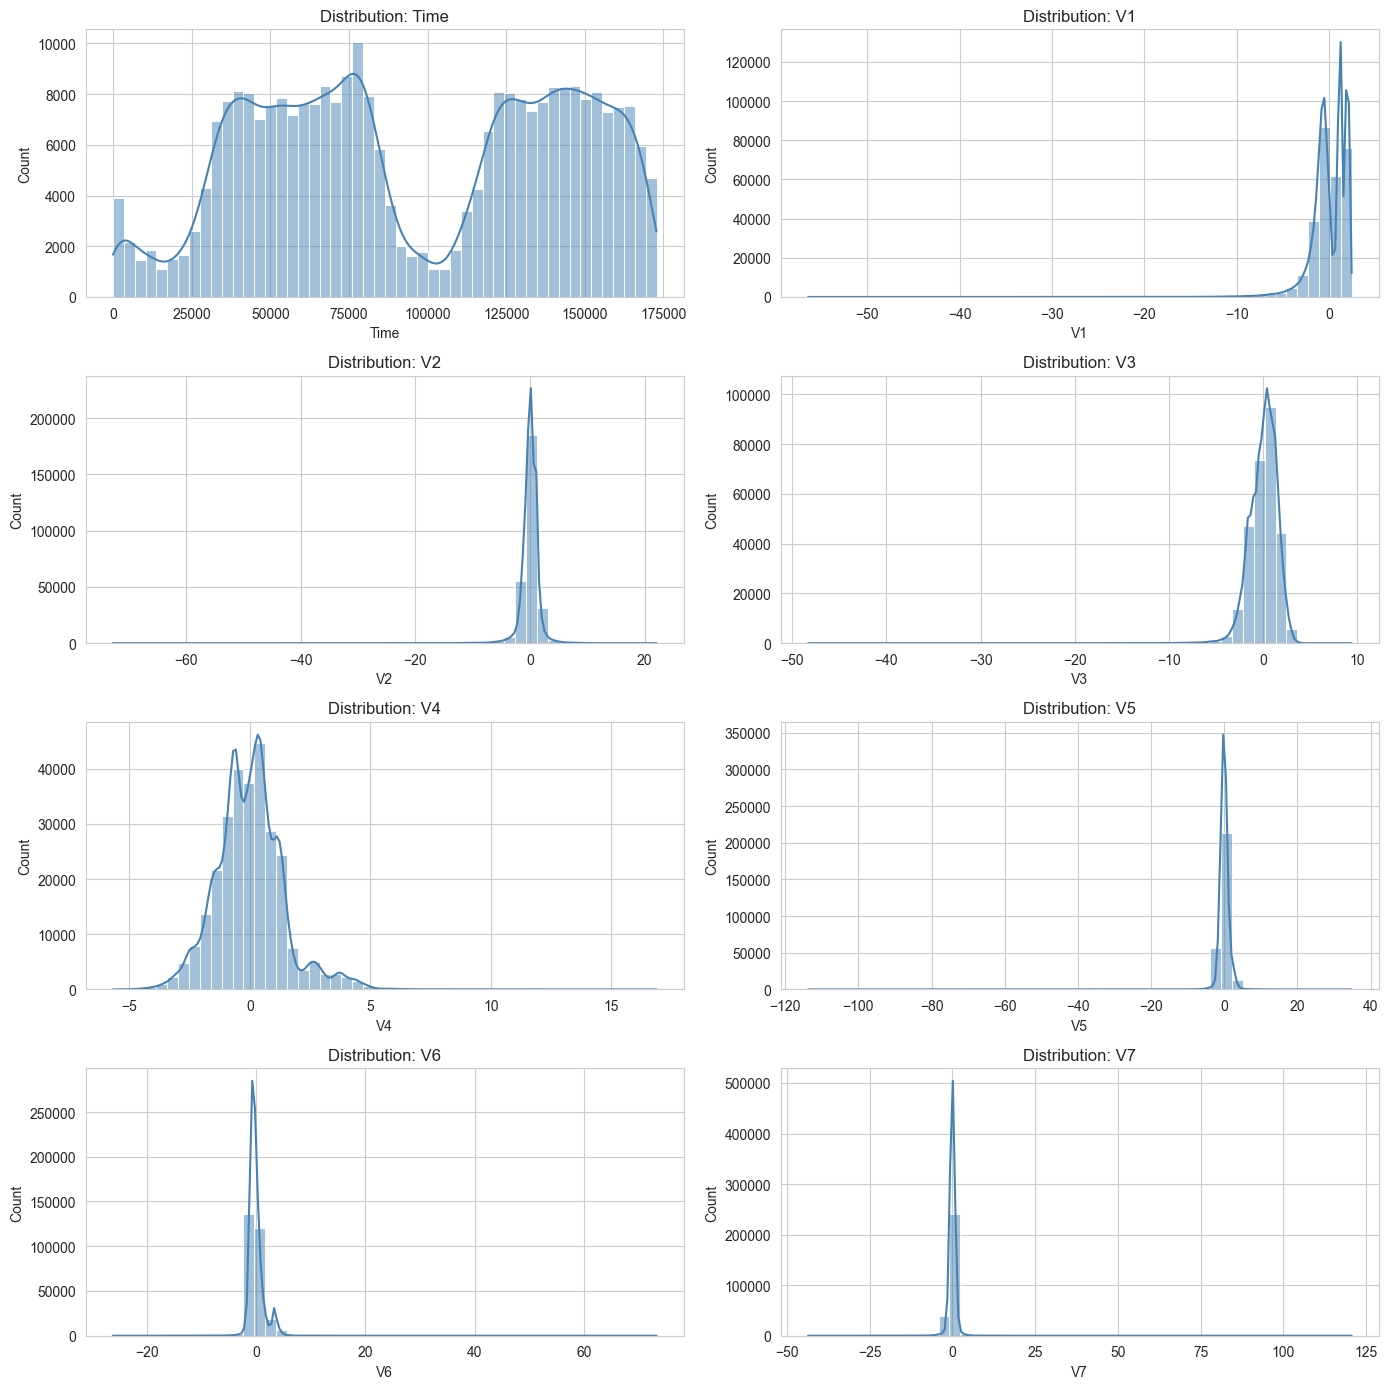

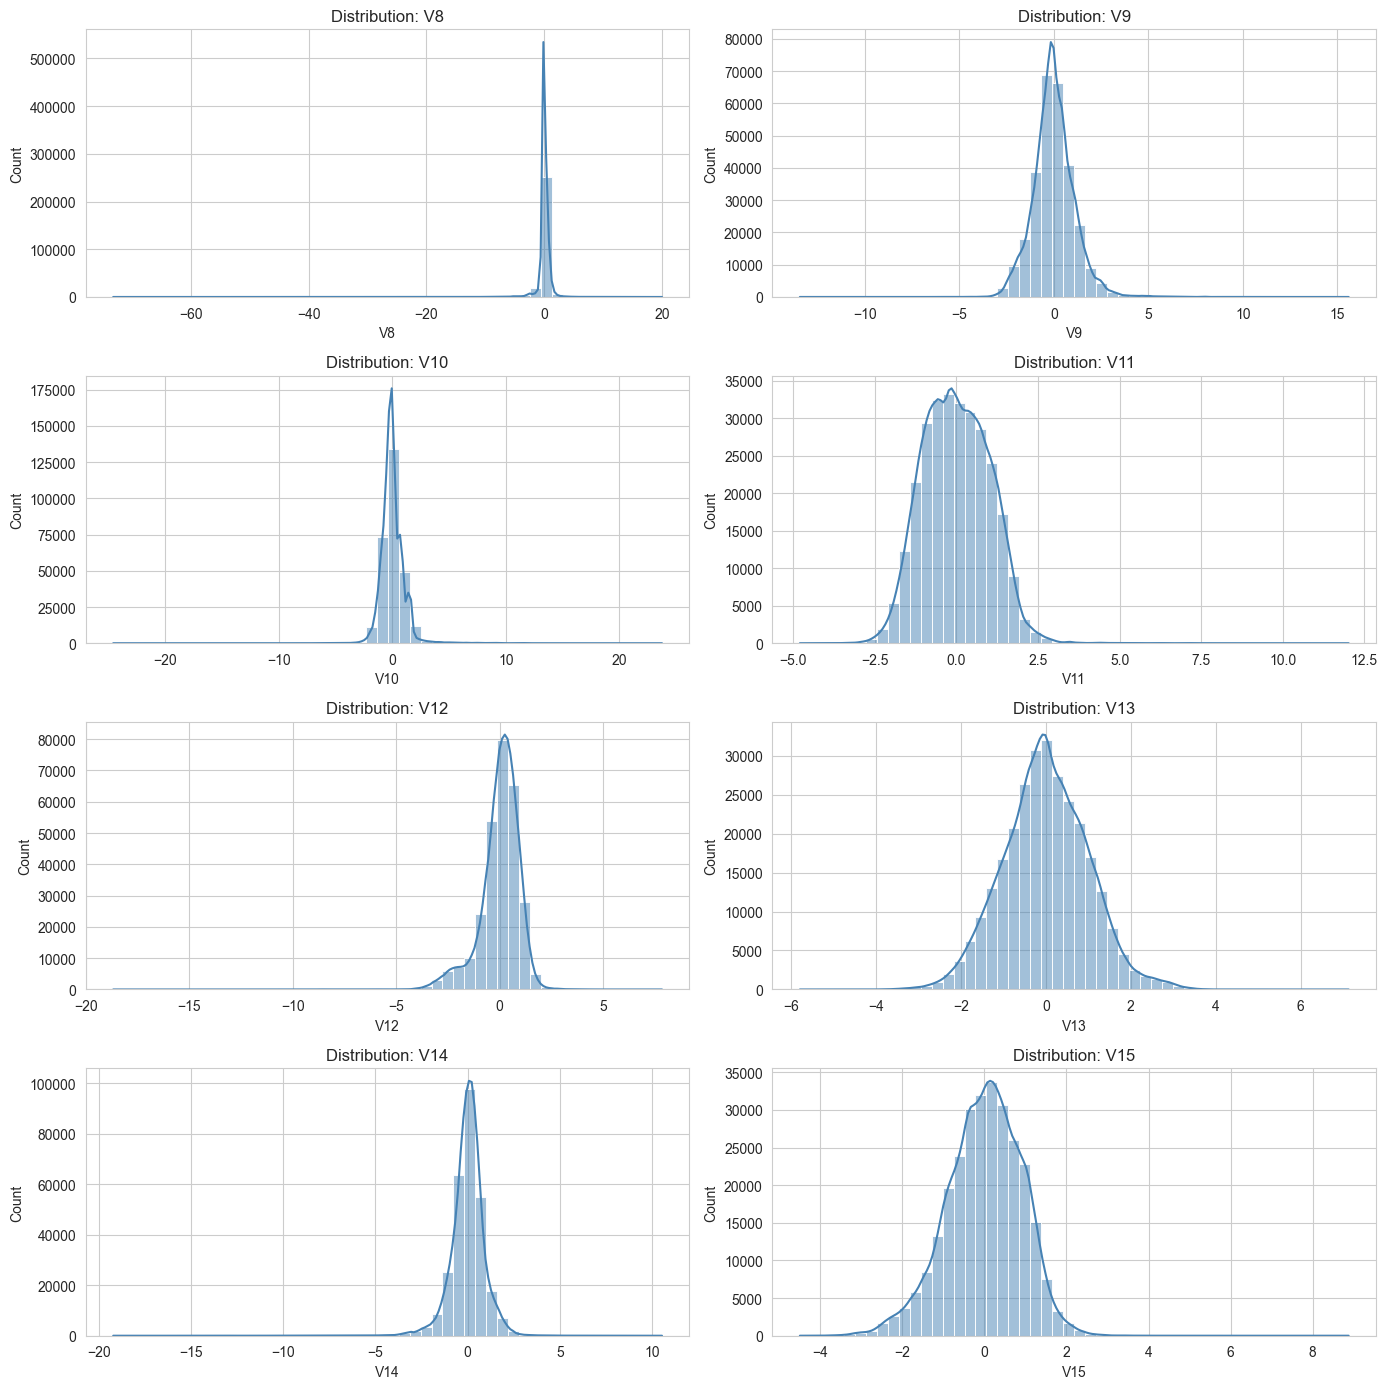

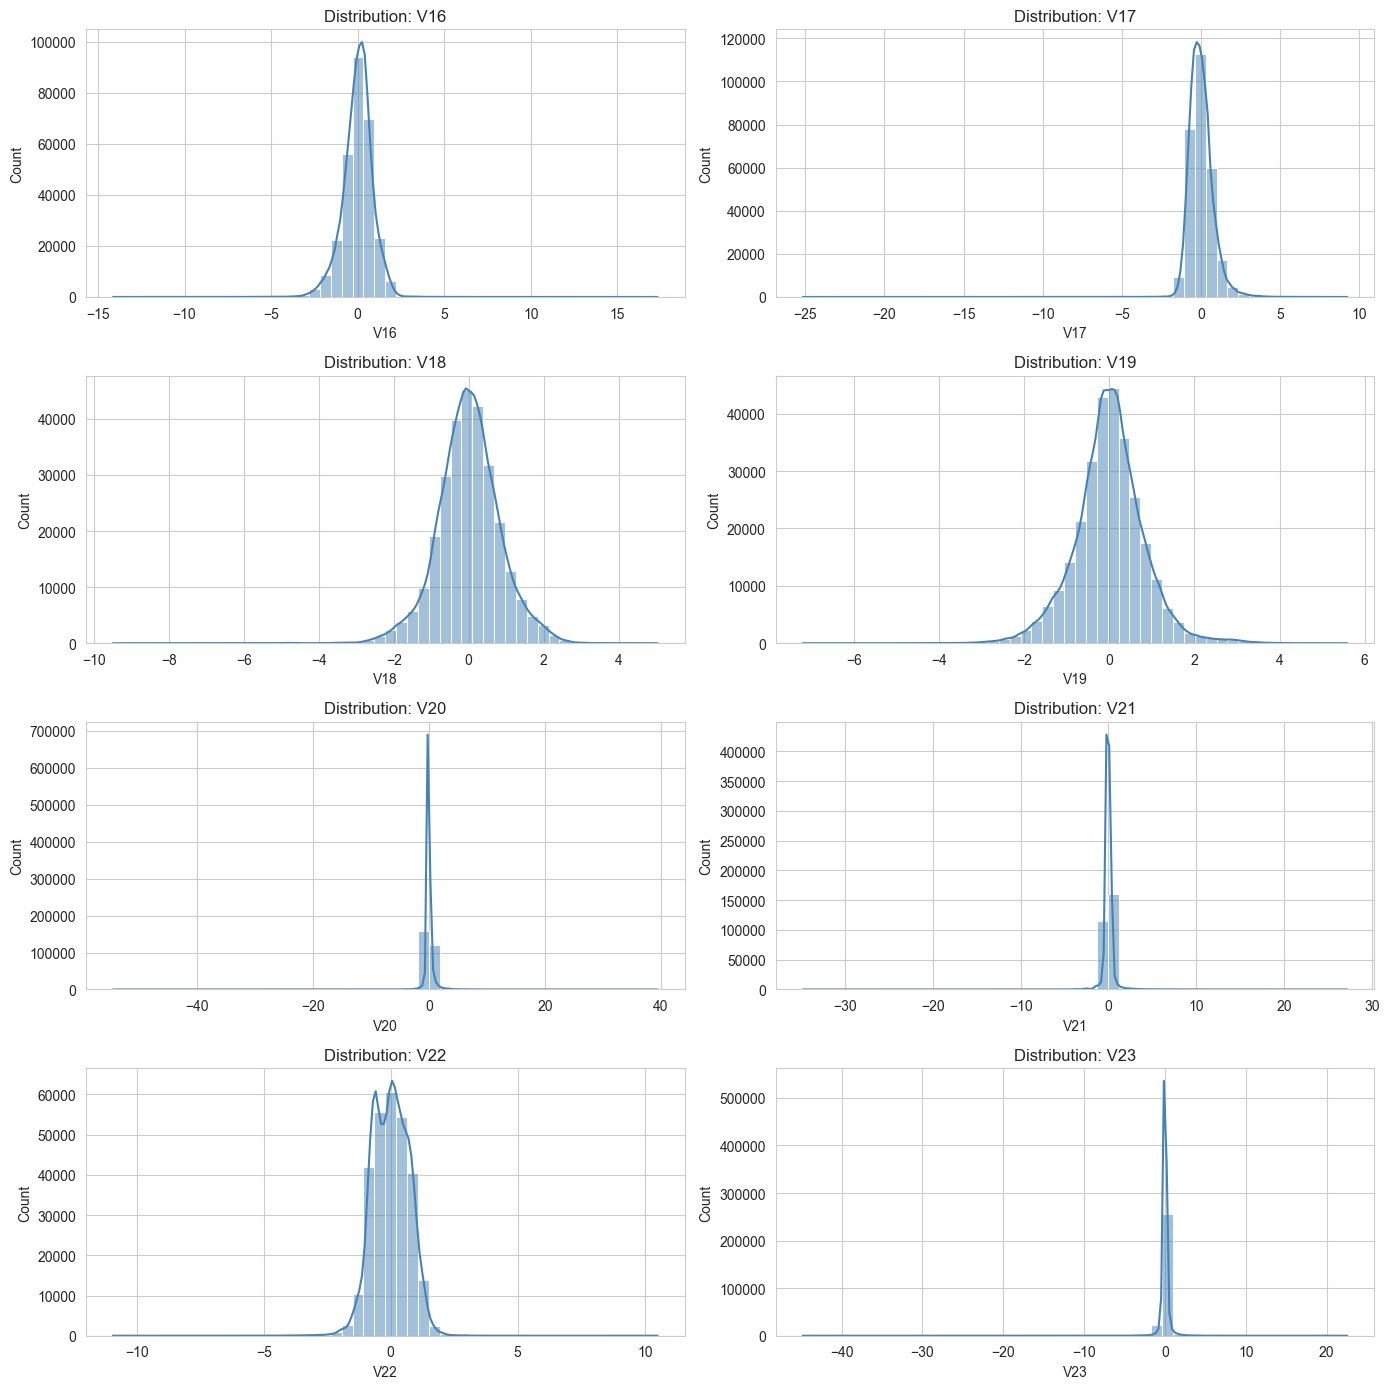

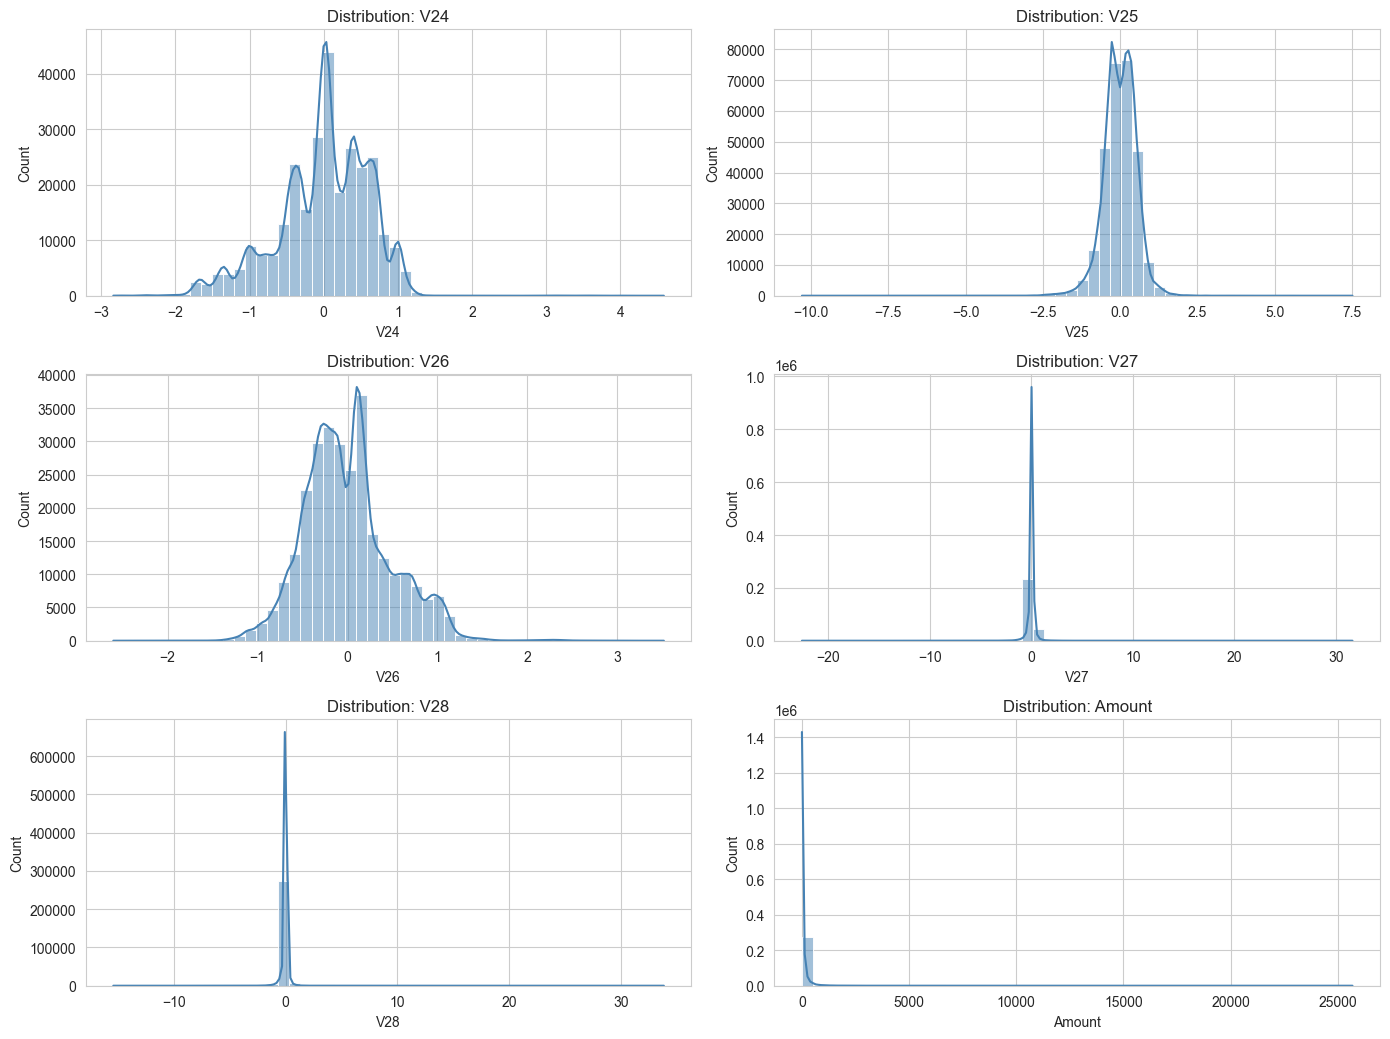

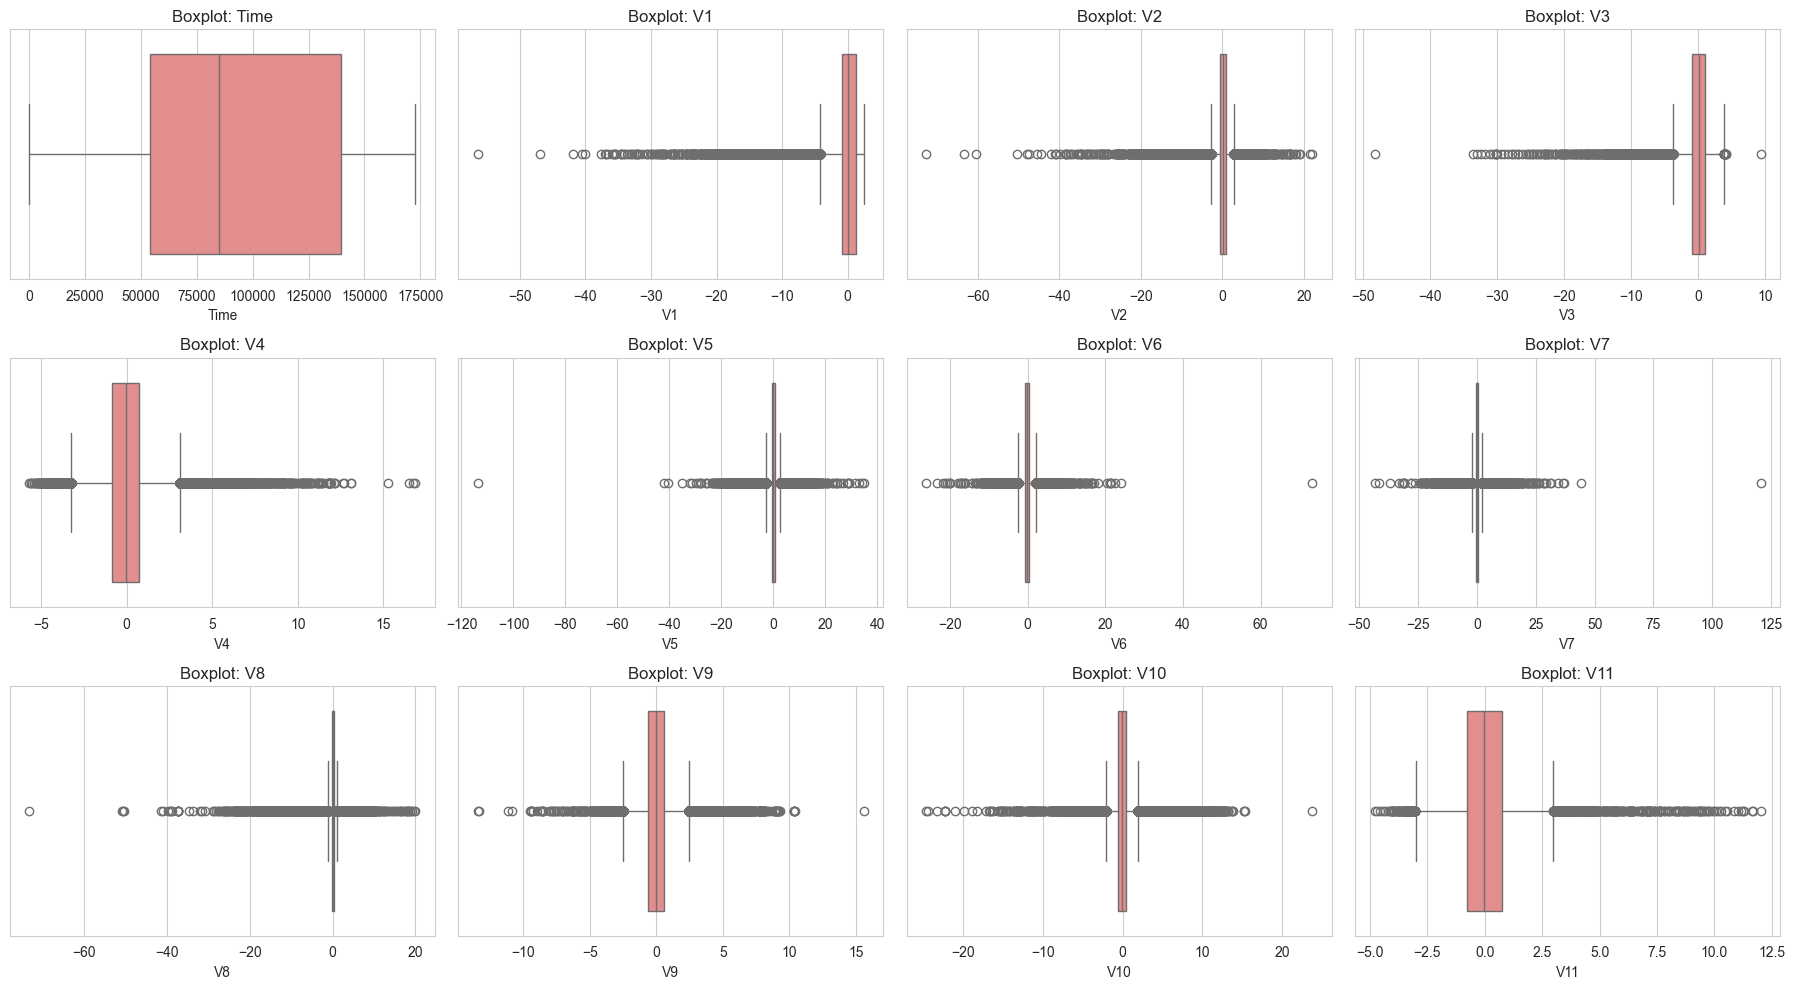

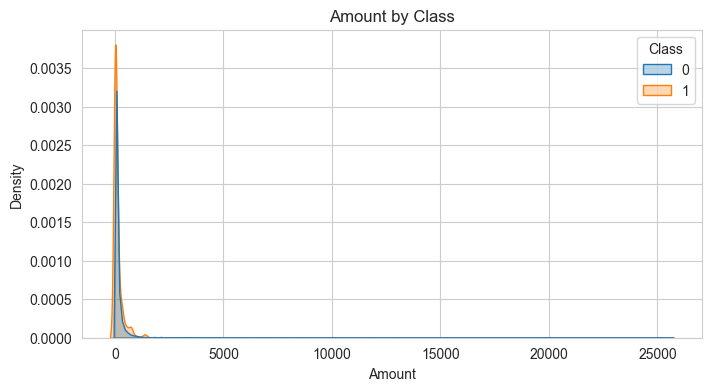

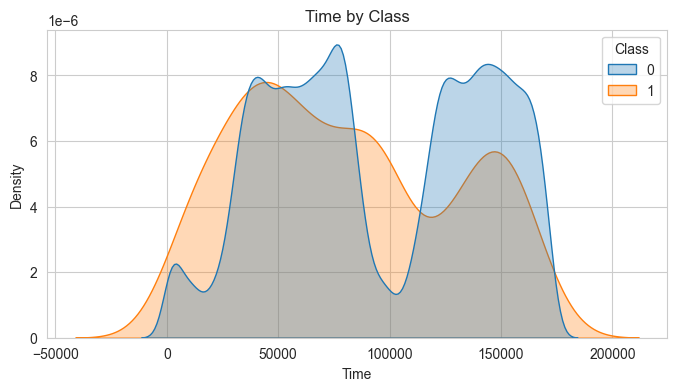

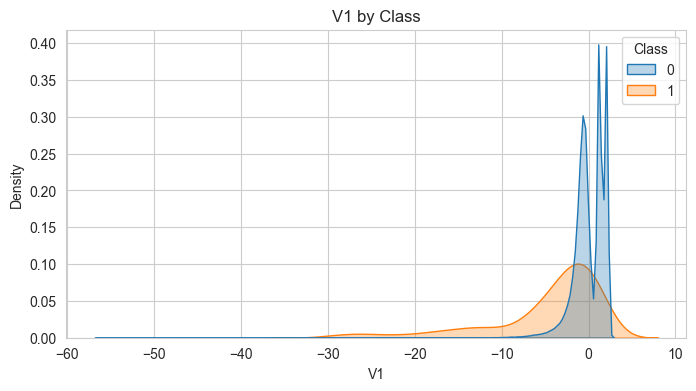

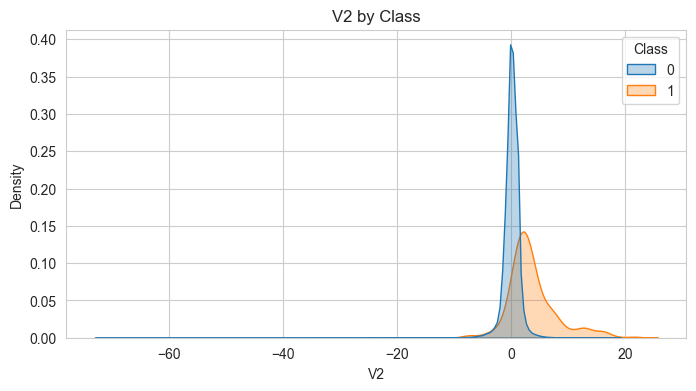

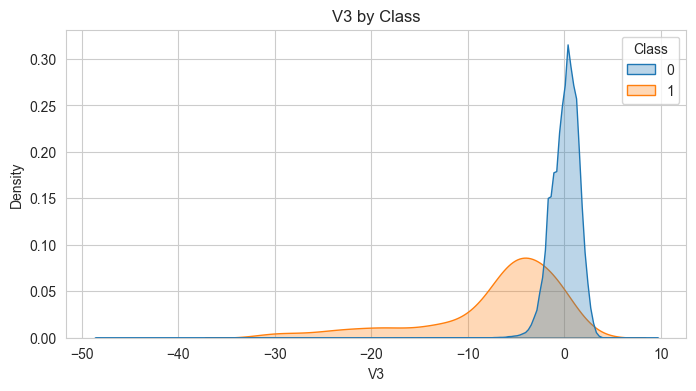

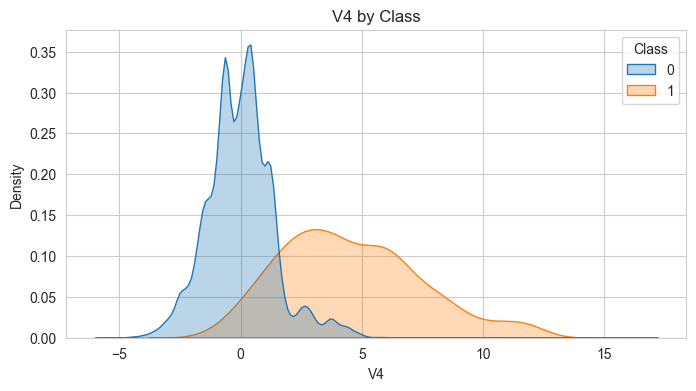

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load data
df = pd.read_csv("creditcard.csv")

# Basic info
print("Shape:", df.shape)
print("\nColumns:\n", df.columns.tolist())
print("\nMissing values:\n", df.isnull().sum().sort_values(ascending=False).head(10))

# Numeric columns
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()

# Optional: exclude target column if present
target_col = "Class" if "Class" in df.columns else None
feature_cols = [c for c in num_cols if c != target_col]

# Summary stats
print("\nSummary statistics:")
display(df[feature_cols].describe().T)

# Skewness (helps identify highly skewed features)
skew_vals = df[feature_cols].skew().sort_values(ascending=False)
print("\nTop 10 most positively skewed features:")
display(skew_vals.head(10))
print("\nTop 10 most negatively skewed features:")
display(skew_vals.tail(10))

# Histograms for all features (chunked to avoid huge single figure)
sns.set_style("whitegrid")
chunk_size = 8
for i in range(0, len(feature_cols), chunk_size):
    cols = feature_cols[i:i+chunk_size]
    n = len(cols)
    fig, axes = plt.subplots((n + 1) // 2, 2, figsize=(14, 3.5 * ((n + 1) // 2)))
    axes = np.array(axes).reshape(-1)

    for j, col in enumerate(cols):
        sns.histplot(df[col], bins=50, kde=True, ax=axes[j], color="steelblue")
        axes[j].set_title(f"Distribution: {col}")

    for k in range(j + 1, len(axes)):
        axes[k].axis("off")

    plt.tight_layout()
    plt.show()

# Boxplots to inspect outliers (first 12 features for readability)
show_cols = feature_cols[:12]
fig, axes = plt.subplots(3, 4, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(show_cols):
    sns.boxplot(x=df[col], ax=axes[i], color="lightcoral")
    axes[i].set_title(f"Boxplot: {col}")

for i in range(len(show_cols), len(axes)):
    axes[i].axis("off")

plt.tight_layout()
plt.show()

# Class-wise distribution comparison (if Class exists)
if target_col is not None:
    compare_cols = ["Amount", "Time"] + [c for c in feature_cols if c.startswith("V")][:4]
    compare_cols = [c for c in compare_cols if c in df.columns]

    for col in compare_cols:
        plt.figure(figsize=(8, 4))
        sns.kdeplot(data=df, x=col, hue=target_col, common_norm=False, fill=True, alpha=0.3)
        plt.title(f"{col} by {target_col}")
        plt.show()

In [ ]:
# 5. PCA for Dimensionality Reduction
pca = PCA(n_components=10) # give the amount fo to infomraiotn to the pca
X_pca = pca.fit_transform(X_scaled)

,Component,Explained Variance Ratio,Cumulative Variance
0,PC1,0.067512,0.067512
1,PC2,0.034483,0.101995
2,PC3,0.034483,0.136477
3,PC4,0.034483,0.170960
4,PC5,0.034483,0.205443
5,PC6,0.034483,0.239926
6,PC7,0.034483,0.274408
7,PC8,0.034483,0.308891
8,PC9,0.034483,0.343374
9,PC10,0.034483,0.377857


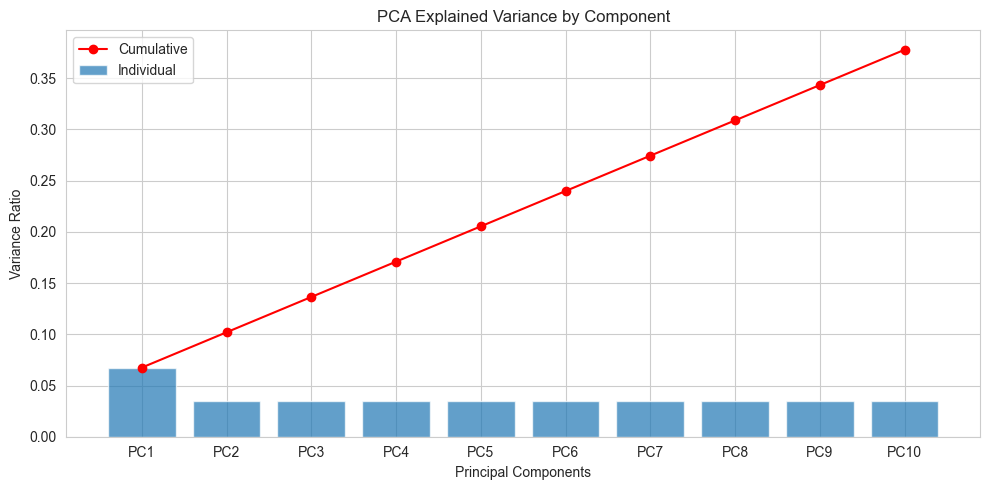

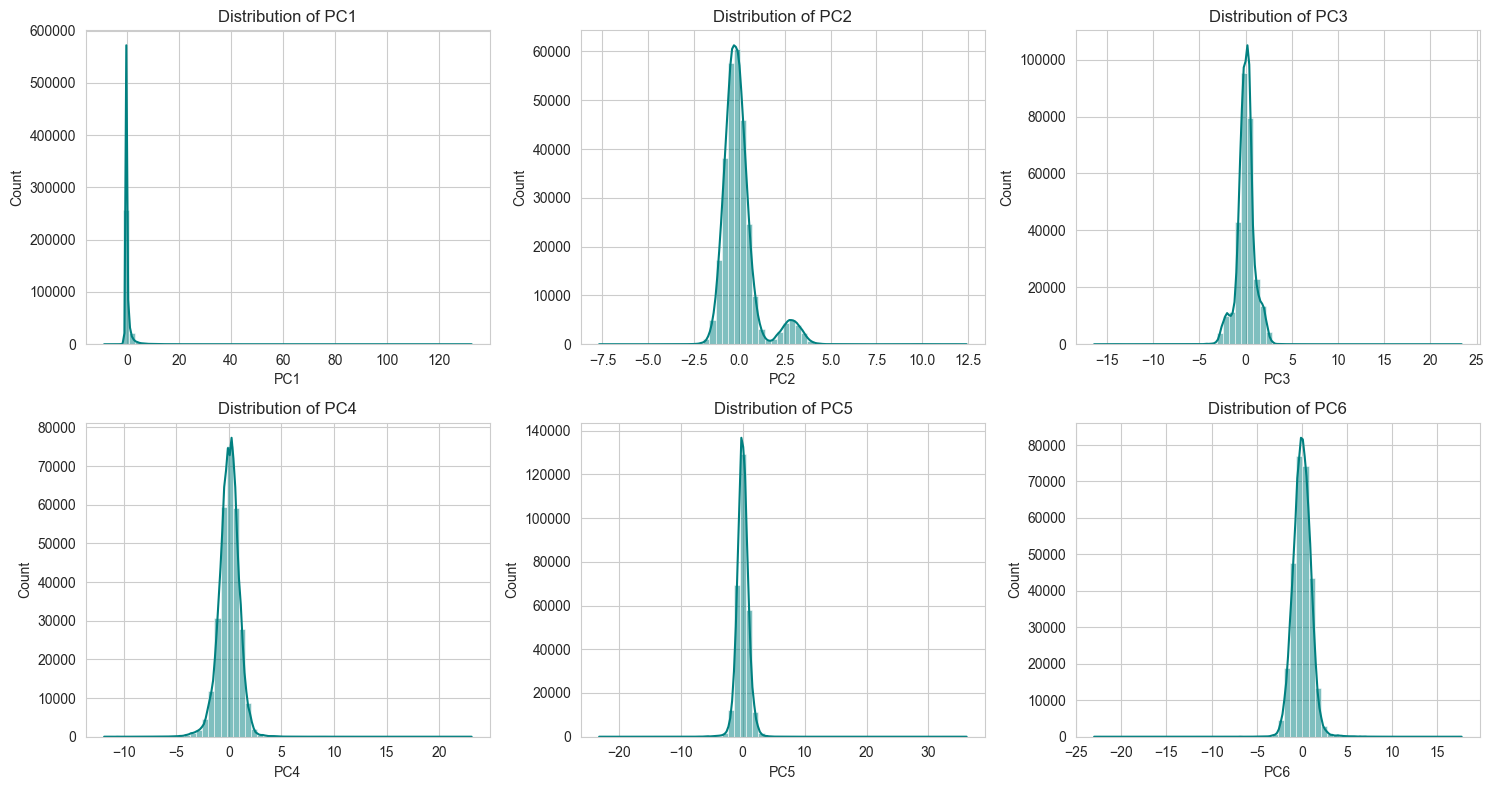

In [7]:
# PCA component distribution overview

n_components_to_show = min(10, X_pca.shape[1])
pc_names = [f"PC{i+1}" for i in range(n_components_to_show)]

# Build dataframe for easy inspection
pc_df = pd.DataFrame(X_pca[:, :n_components_to_show], columns=pc_names)

# Explained variance
explained_df = pd.DataFrame({
    "Component": pc_names,
    "Explained Variance Ratio": pca.explained_variance_ratio_[:n_components_to_show]
})
explained_df["Cumulative Variance"] = explained_df["Explained Variance Ratio"].cumsum()

display(explained_df)

# Plot explained variance + cumulative variance
plt.figure(figsize=(10, 5))
plt.bar(explained_df["Component"], explained_df["Explained Variance Ratio"], alpha=0.7, label="Individual")
plt.plot(explained_df["Component"], explained_df["Cumulative Variance"], marker="o", color="red", label="Cumulative")
plt.title("PCA Explained Variance by Component")
plt.xlabel("Principal Components")
plt.ylabel("Variance Ratio")
plt.legend()
plt.tight_layout()
plt.show()

# Distribution of first few principal components
k = min(6, n_components_to_show)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i in range(k):
    sns.histplot(pc_df.iloc[:, i], bins=60, kde=True, ax=axes[i], color="teal")
    axes[i].set_title(f"Distribution of {pc_names[i]}")

for i in range(k, len(axes)):
    axes[i].axis("off")

plt.tight_layout()
plt.show()

Data Loaded. Shape: (284807, 31)

Class Distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Percentage Distribution:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64
[-8.50701717e-04 -2.18653296e-03 -5.34231408e-04 -9.58610503e-04
 -4.46847505e-05 -1.14391241e-04  1.14370901e-03 -5.73531494e-04
  2.03346002e-04 -1.81782769e-04]

Best epsilon: 6.72666e-08
Best F1 score on validation: 0.0214

Confusion Matrix on Validation Set:
[[48746  8118]
 [    9    89]]


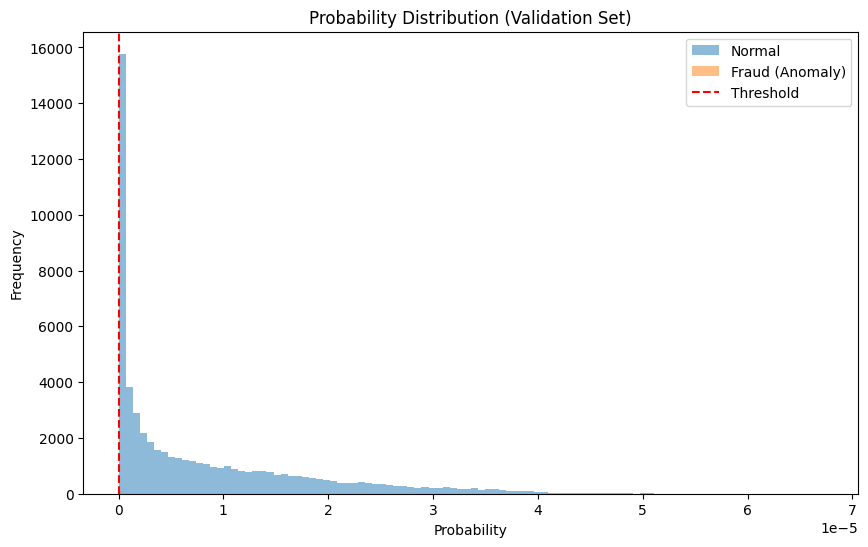

In [3]:
# 6. Train-Validation Split
X_train, X_val, y_train, y_val = train_test_split(X_pca, y_true, test_size=0.2, stratify=y_true, random_state=42)

# 7. Estimate Gaussian Parameters from Training Set
mu = np.mean(X_train, axis=0)
print(mu)
sigma = np.cov(X_train, rowvar=False)
gaussian_model = multivariate_normal(mean=mu, cov=sigma)

# 8. Probability Values
p_train = gaussian_model.pdf(X_train)
p_val = gaussian_model.pdf(X_val)

# 9. Select Threshold Using Validation Set
def select_threshold(p_vals, y_true):
    best_epsilon = 0
    best_f1 = 0
    epsilons = np.linspace(min(p_vals), max(p_vals), 1000)
    for epsilon in epsilons:
        preds = (p_vals < epsilon).astype(int)
        f1 = f1_score(y_true, preds)
        if f1 > best_f1:
            best_f1 = f1
            best_epsilon = epsilon
    return best_epsilon, best_f1

epsilon, f1 = select_threshold(p_val, y_val)
print(f"\nBest epsilon: {epsilon:.5e}")
print(f"Best F1 score on validation: {f1:.4f}")

# 10. Predict Anomalies on Validation Set
y_pred = (p_val < epsilon).astype(int)
cm = confusion_matrix(y_val, y_pred)
print("\nConfusion Matrix on Validation Set:")
print(cm)

# 11. Plot Probability Distribution
plt.figure(figsize=(10, 6))
plt.hist(p_val[y_val == 0], bins=100, alpha=0.5, label='Normal')
plt.hist(p_val[y_val == 1], bins=100, alpha=0.5, label='Fraud (Anomaly)')
plt.axvline(x=epsilon, color='r', linestyle='--', label='Threshold')
plt.legend()
plt.title('Probability Distribution (Validation Set)')
plt.xlabel('Probability')
plt.ylabel('Frequency')
plt.show()


,Metric,Value
0,Accuracy,0.888645
1,Balanced Accuracy,0.867828
2,Precision,0.012946
3,Recall (TPR),0.846939
4,Specificity (TNR),0.888717
5,F1 Score,0.025503
6,MCC,0.096467
7,ROC AUC,0.060628
8,PR AUC,0.037767
9,False Positive Rate,0.111283


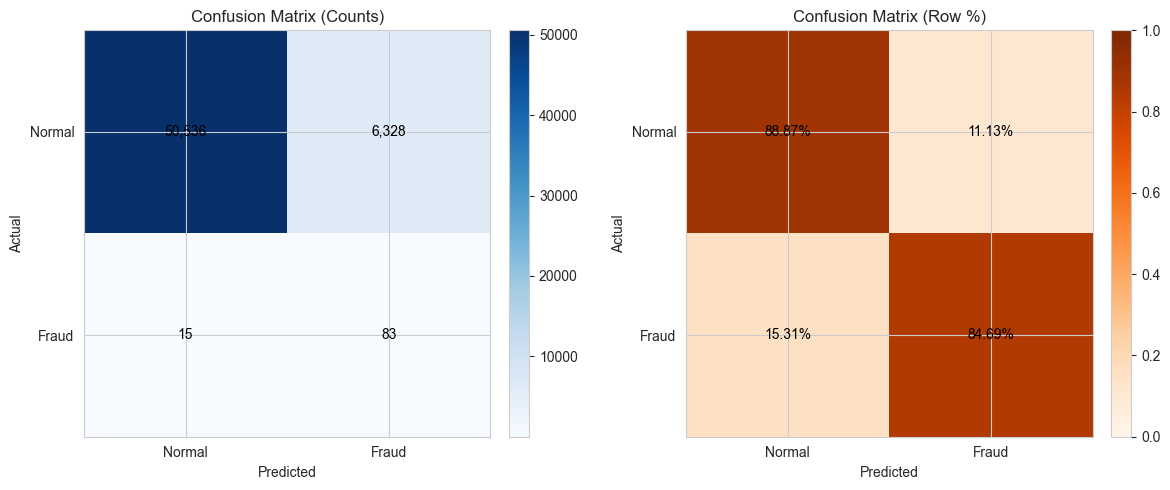

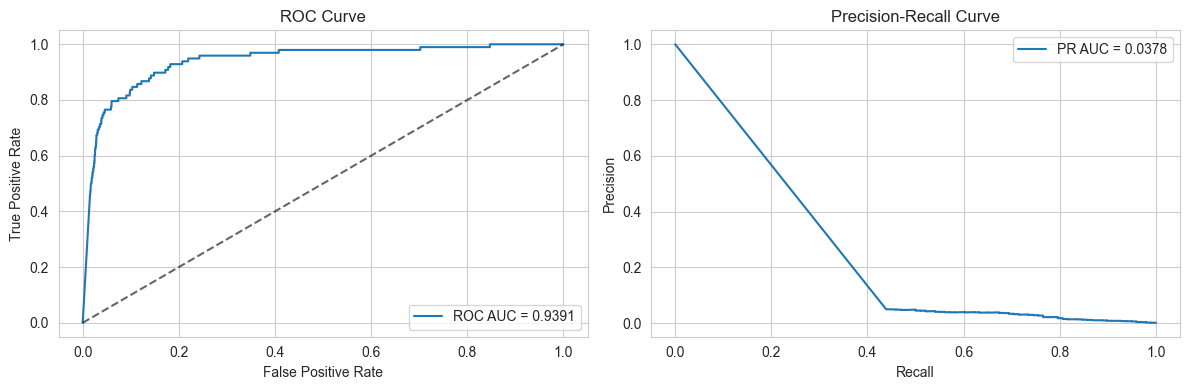

In [10]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    roc_curve,
    precision_recall_curve,
)

# Use existing predictions/scores
# y_pred = (p_val < epsilon).astype(int)  # already available
cm = confusion_matrix(y_val, y_pred)
tn, fp, fn, tp = cm.ravel()

# Core metrics
specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0
fpr_value = fp / (fp + tn) if (fp + tn) > 0 else 0.0
fnr_value = fn / (fn + tp) if (fn + tp) > 0 else 0.0

metrics_df = pd.DataFrame({
    "Metric": [
        "Accuracy", "Balanced Accuracy", "Precision", "Recall (TPR)",
        "Specificity (TNR)", "F1 Score", "MCC", "ROC AUC", "PR AUC",
        "False Positive Rate", "False Negative Rate"
    ],
    "Value": [
        accuracy_score(y_val, y_pred),
        balanced_accuracy_score(y_val, y_pred),
        precision_score(y_val, y_pred, zero_division=0),
        recall_score(y_val, y_pred, zero_division=0),
        specificity,
        f1_score(y_val, y_pred, zero_division=0),
        matthews_corrcoef(y_val, y_pred),
        roc_auc_score(y_val, p_val),
        average_precision_score(y_val, 1 - p_val),  # lower p_val => more anomalous
        fpr_value,
        fnr_value,
    ]
})

display(metrics_df)

# Better confusion matrix visualization: counts + row-wise normalized %
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Counts
im0 = axes[0].imshow(cm, cmap="Blues")
axes[0].set_title("Confusion Matrix (Counts)")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")
axes[0].set_xticks([0, 1]); axes[0].set_yticks([0, 1])
axes[0].set_xticklabels(["Normal", "Fraud"])
axes[0].set_yticklabels(["Normal", "Fraud"])
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, f"{cm[i, j]:,}", ha="center", va="center", color="black")
fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

# Normalized
im1 = axes[1].imshow(cm_norm, cmap="Oranges", vmin=0, vmax=1)
axes[1].set_title("Confusion Matrix (Row %)")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")
axes[1].set_xticks([0, 1]); axes[1].set_yticks([0, 1])
axes[1].set_xticklabels(["Normal", "Fraud"])
axes[1].set_yticklabels(["Normal", "Fraud"])
for i in range(2):
    for j in range(2):
        axes[1].text(j, i, f"{cm_norm[i, j]*100:.2f}%", ha="center", va="center", color="black")
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

# ROC and Precision-Recall curves
fpr, tpr, _ = roc_curve(y_val, 1 - p_val)  # higher score => more anomalous
prec, rec, _ = precision_recall_curve(y_val, 1 - p_val)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(fpr, tpr, label=f"ROC AUC = {roc_auc_score(y_val, 1 - p_val):.4f}")
plt.plot([0, 1], [0, 1], "k--", alpha=0.6)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(rec, prec, label=f"PR AUC = {average_precision_score(y_val, 1 - p_val):.4f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()

plt.tight_layout()
plt.show()